In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEED = 42
np.random.seed(SEED)

# --- Opción A: subir el archivo manualmente ---
from google.colab import files
uploaded = files.upload()          # selecciona EngineFaultDB_Final.csv
df = pd.read_csv("EngineFaultDB_Final.csv")

# --- Opción B: desde Drive (descomenta si prefieres) ---
# from google.colab import drive
# drive.mount('/content/drive')
# df = pd.read_csv("/content/drive/MyDrive/RUTA/EngineFaultDB_Final.csv")

print(df.shape)
print(df['Fault'].value_counts().sort_index())

Saving EngineFaultDB_Final.csv to EngineFaultDB_Final.csv
(55999, 15)
Fault
0    16000
1    10998
2    15000
3    14001
Name: count, dtype: int64


In [2]:
TARGET = "Fault"
FEATURES = [c for c in df.columns if c != TARGET]   # las 14 variables

X = df[FEATURES].values
y = df[TARGET].values

# Split 80/20 estratificado (igual que el paper del dataset).
# El test NO se toca hasta la evaluación final.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Validación cruzada estratificada de 5 folds sobre el set de entrenamiento
K = 5
cv = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)

Train: (44799, 14) | Test: (11200, 14)


In [3]:
param_grid = {
    "rf__n_estimators":     [50, 100, 200],
    "rf__max_depth":        [5, 10, 20, None],
    "rf__min_samples_leaf": [1, 5, 10],
    "rf__max_features":     ["sqrt", 0.5],
}

grid_table = pd.DataFrame({
    "Hiperparámetro": ["n_estimators", "max_depth", "min_samples_leaf", "max_features"],
    "Descripción": ["Número de árboles del ensamble",
                    "Profundidad máxima de cada árbol",
                    "Mínimo de muestras por hoja",
                    "Variables consideradas en cada división"],
    "Valores evaluados": [str(v) for v in param_grid.values()],
})
display(grid_table)   # Tabla para el reporte
print("Combinaciones:", np.prod([len(v) for v in param_grid.values()]), "x", K, "folds")

,Hiperparámetro,Descripción,Valores evaluados
0,n_estimators,Número de árboles del ensamble,"[50, 100, 200]"
1,max_depth,Profundidad máxima de cada árbol,"[5, 10, 20, None]"
2,min_samples_leaf,Mínimo de muestras por hoja,"[1, 5, 10]"
3,max_features,Variables consideradas en cada división,"['sqrt', 0.5]"


Combinaciones: 72 x 5 folds


In [4]:
def mean_ci(scores, conf=0.95):
    """Media e intervalo de confianza (t de Student) sobre los folds."""
    scores = np.asarray(scores)
    m = scores.mean()
    h = stats.sem(scores) * stats.t.ppf((1 + conf) / 2, len(scores) - 1)
    return m, h

def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, conf=0.95, seed=SEED):
    """IC por bootstrap para las métricas en test."""
    rng = np.random.RandomState(seed)
    n = len(y_true)
    vals = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        vals.append(metric(y_true[idx], y_pred[idx]))
    lo, hi = np.percentile(vals, [(1-conf)/2*100, (1+conf)/2*100])
    return np.mean(vals), lo, hi

SCORING = {
    "accuracy":  "accuracy",
    "precision": "precision_macro",
    "recall":    "recall_macro",
    "f1":        "f1_macro",
}

def run_rf(Xtr, ytr, Xte, yte, grid, name="Original", scale=True):
    """
    Ajusta hiperparámetros con CV, reporta train/val (con IC) y test (con IC).
    Reutilizable para PCA / UMAP (pasar Xtr, Xte ya transformados).
    """
    steps = []
    if scale:
        steps.append(("scaler", StandardScaler()))   # no afecta a los árboles; por consistencia
    steps.append(("rf", RandomForestClassifier(random_state=SEED, n_jobs=-1)))
    pipe = Pipeline(steps)

    gs = GridSearchCV(pipe, grid, cv=cv, scoring=SCORING, refit="f1",
                      return_train_score=True, n_jobs=-1, verbose=1)
    gs.fit(Xtr, ytr)
    best = gs.best_estimator_
    print(f"\n[{name}] Mejores hiperparámetros: {gs.best_params_}")

    # Train / Validación con IC (por fold) del mejor modelo
    cvres = cross_validate(best, Xtr, ytr, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
    rows = []
    for m in SCORING:
        tr_m, tr_h = mean_ci(cvres[f"train_{m}"])
        va_m, va_h = mean_ci(cvres[f"test_{m}"])
        rows.append([m, f"{tr_m:.4f} ± {tr_h:.4f}", f"{va_m:.4f} ± {va_h:.4f}"])

    # Test con IC bootstrap
    yp = best.predict(Xte)
    metric_fns = {
        "accuracy":  accuracy_score,
        "precision": lambda a, b: precision_score(a, b, average="macro", zero_division=0),
        "recall":    lambda a, b: recall_score(a, b, average="macro", zero_division=0),
        "f1":        lambda a, b: f1_score(a, b, average="macro"),
    }
    for r in rows:
        m_, lo, hi = bootstrap_ci(yte, yp, metric_fns[r[0]])
        r.append(f"{m_:.4f} [{lo:.4f}, {hi:.4f}]")

    results = pd.DataFrame(rows, columns=["Métrica", "Train (media ± IC95)",
                                          "Validación (media ± IC95)", "Test (media [IC95])"])
    return gs, best, yp, results

In [5]:
gs_rf, best_rf, y_pred_rf, res_rf = run_rf(X_train, y_train, X_test, y_test, param_grid, name="RF - Original")
display(res_rf)

print("\nReporte de clasificación (test):")
print(classification_report(y_test, y_pred_rf, digits=4))

Fitting 5 folds for each of 72 candidates, totalling 360 fits

[RF - Original] Mejores hiperparámetros: {'rf__max_depth': 10, 'rf__max_features': 0.5, 'rf__min_samples_leaf': 5, 'rf__n_estimators': 50}


,Métrica,Train (media ± IC95),Validación (media ± IC95),Test (media [IC95])
0,accuracy,0.8443 ± 0.0034,0.7525 ± 0.0015,"0.7442 [0.7362, 0.7521]"
1,precision,0.8498 ± 0.0030,0.7605 ± 0.0017,"0.7519 [0.7456, 0.7584]"
2,recall,0.8492 ± 0.0039,0.7605 ± 0.0017,"0.7521 [0.7458, 0.7585]"
3,f1,0.8492 ± 0.0038,0.7602 ± 0.0018,"0.7517 [0.7453, 0.7579]"



Reporte de clasificación (test):
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      3200
           1     0.9986    1.0000    0.9993      2200
           2     0.5211    0.5567    0.5383      3000
           3     0.4877    0.4514    0.4688      2800

    accuracy                         0.7441     11200
   macro avg     0.7518    0.7520    0.7516     11200
weighted avg     0.7434    0.7441    0.7434     11200



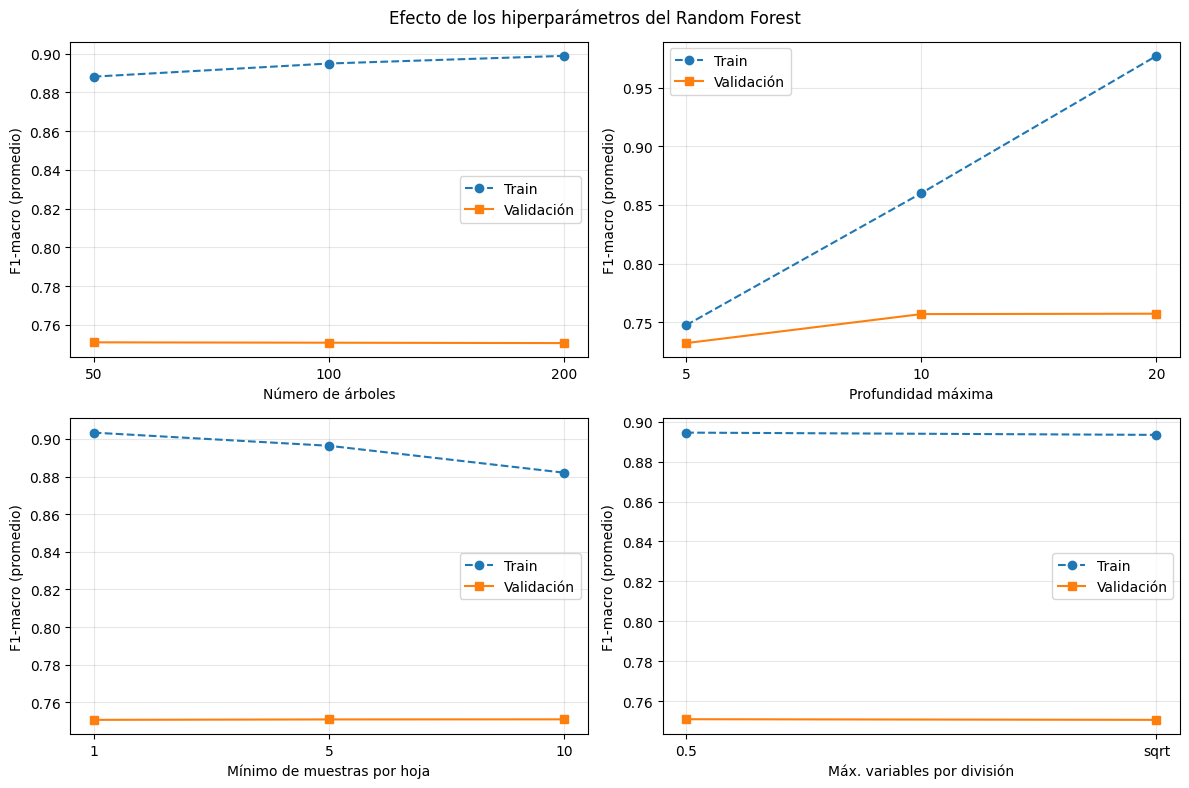

In [6]:
cvr = pd.DataFrame(gs_rf.cv_results_)

hparams = {
    "param_rf__n_estimators":     "Número de árboles",
    "param_rf__max_depth":        "Profundidad máxima",
    "param_rf__min_samples_leaf": "Mínimo de muestras por hoja",
    "param_rf__max_features":     "Máx. variables por división",
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, label) in zip(axes.ravel(), hparams.items()):
    g = cvr.groupby(col).agg(val=("mean_test_f1", "mean"),
                             tr=("mean_train_f1", "mean")).reset_index()
    g[col] = g[col].astype(str)
    ax.plot(g[col], g["tr"], "o--", label="Train")
    ax.plot(g[col], g["val"], "s-", label="Validación")
    ax.set_xlabel(label); ax.set_ylabel("F1-macro (promedio)")
    ax.grid(alpha=.3); ax.legend()
fig.suptitle("Efecto de los hiperparámetros del Random Forest")
plt.tight_layout(); plt.show()

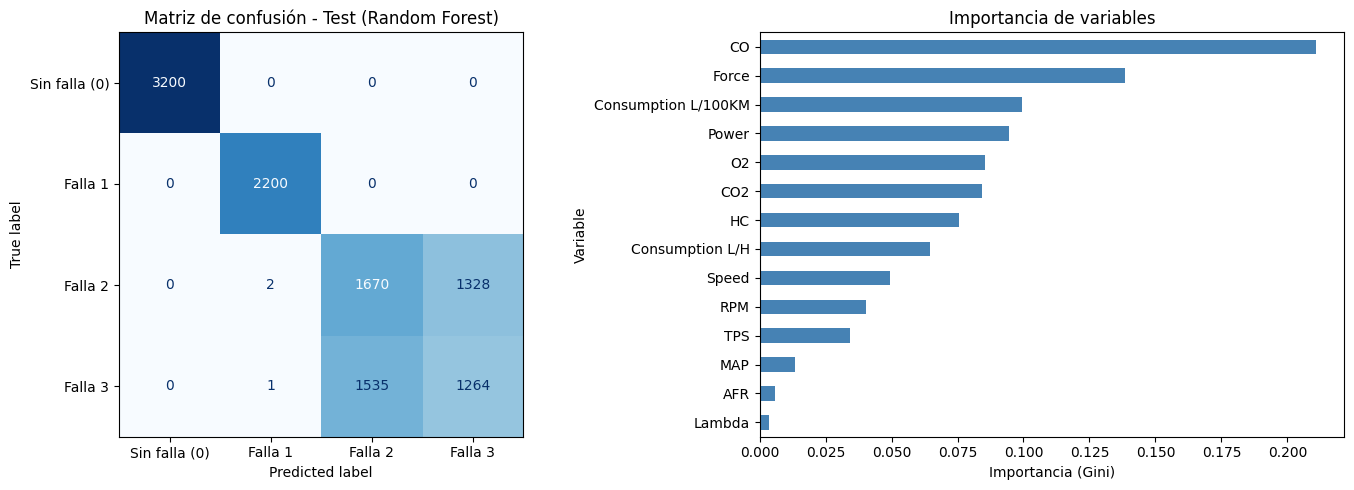

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred_rf)
ConfusionMatrixDisplay(cm, display_labels=["Sin falla (0)", "Falla 1", "Falla 2", "Falla 3"]).plot(
    ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Matriz de confusión - Test (Random Forest)")

imp = pd.Series(best_rf.named_steps["rf"].feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(ax=ax[1], color="steelblue")
ax[1].set_xlabel("Importancia (Gini)"); ax[1].set_ylabel("Variable")
ax[1].set_title("Importancia de variables")
plt.tight_layout(); plt.show()

### Implementación de PCA (Análisis de Componentes Principales)

Antes de entrenar el modelo, ajustamos un PCA sobre los datos de entrenamiento para analizar cuánta varianza explican los componentes y determinar un número adecuado de dimensiones.

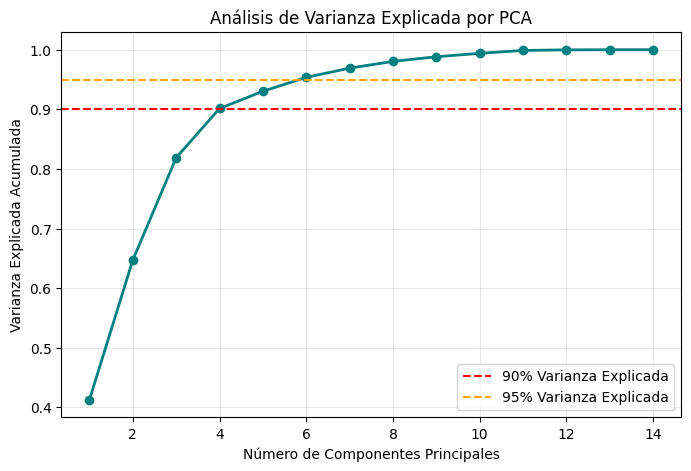

Número de componentes para explicar >= 95% de la varianza: 6


In [8]:
from sklearn.decomposition import PCA

# Es necesario estandarizar los datos antes de aplicar PCA
scaler_pca = StandardScaler()
X_train_scaled = scaler_pca.fit_transform(X_train)
X_test_scaled = scaler_pca.transform(X_test)

# Inicializamos PCA sin límite de componentes para evaluar la varianza acumulada
pca_full = PCA(random_state=SEED)
pca_full.fit(X_train_scaled)

# Calculamos la varianza explicada acumulada
var_acumulada = np.cumsum(pca_full.explained_variance_ratio_)

# Graficamos la varianza explicada acumulada
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(var_acumulada) + 1), var_acumulada, 'o-', color='teal', linewidth=2)
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Varianza Explicada')
plt.axhline(y=0.95, color='orange', linestyle='--', label='95% Varianza Explicada')
plt.xlabel('Número de Componentes Principales')
plt.ylabel('Varianza Explicada Acumulada')
plt.title('Análisis de Varianza Explicada por PCA')
plt.legend(loc='best')
plt.grid(alpha=0.3)
plt.show()

# Buscamos cuántos componentes se necesitan para el 95% de la varianza
n_comp_95 = np.argmax(var_acumulada >= 0.95) + 1
print(f"Número de componentes para explicar >= 95% de la varianza: {n_comp_95}")

### Aplicación del PCA y Re-evaluación del Random Forest

Aplicaremos PCA reduciendo a los componentes que explican la mayor parte de la información y ejecutaremos la búsqueda de hiperparámetros de nuevo.

In [9]:
# Ajustamos PCA con el número de componentes que explican el 95% de la varianza (o puedes modificarlo manualmente)
pca = PCA(n_components=n_comp_95, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Nuevas dimensiones: Train: {X_train_pca.shape} | Test: {X_test_pca.shape}")

# Ejecutamos el modelo RF sobre el dataset con PCA.
# Nota: Ponemos scale=False porque ya escalamos previamente los datos para el PCA.
gs_rf_pca, best_rf_pca, y_pred_rf_pca, res_rf_pca = run_rf(
    X_train_pca, y_train, X_test_pca, y_test, param_grid, name="RF - PCA", scale=False
)

display(res_rf_pca)

print("\nReporte de clasificación con PCA (test):")
print(classification_report(y_test, y_pred_rf_pca, digits=4))

Nuevas dimensiones: Train: (44799, 6) | Test: (11200, 6)
Fitting 5 folds for each of 72 candidates, totalling 360 fits

[RF - PCA] Mejores hiperparámetros: {'rf__max_depth': None, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 1, 'rf__n_estimators': 100}


,Métrica,Train (media ± IC95),Validación (media ± IC95),Test (media [IC95])
0,accuracy,1.0000 ± 0.0000,0.7508 ± 0.0066,"0.7452 [0.7363, 0.7535]"
1,precision,1.0000 ± 0.0000,0.7587 ± 0.0065,"0.7537 [0.7470, 0.7603]"
2,recall,1.0000 ± 0.0000,0.7589 ± 0.0063,"0.7535 [0.7468, 0.7601]"
3,f1,1.0000 ± 0.0000,0.7588 ± 0.0063,"0.7536 [0.7468, 0.7602]"



Reporte de clasificación con PCA (test):
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      3200
           1     1.0000    0.9986    0.9993      2200
           2     0.5239    0.5293    0.5266      3000
           3     0.4903    0.4854    0.4878      2800

    accuracy                         0.7450     11200
   macro avg     0.7535    0.7533    0.7534     11200
weighted avg     0.7450    0.7450    0.7450     11200



### Comparación de Modelos: Original vs. PCA

Analicemos el impacto en el rendimiento de aplicar reducción de dimensionalidad con PCA.

In [10]:
# Unimos los resultados de Test para comparar
comparativa = pd.DataFrame({
    "Métrica": res_rf["Métrica"],
    "Modelo Original (Test)": res_rf["Test (media [IC95])"],
    "Modelo con PCA (Test)": res_rf_pca["Test (media [IC95])"]
})
display(comparativa)

,Métrica,Modelo Original (Test),Modelo con PCA (Test)
0,accuracy,"0.7442 [0.7362, 0.7521]","0.7452 [0.7363, 0.7535]"
1,precision,"0.7519 [0.7456, 0.7584]","0.7537 [0.7470, 0.7603]"
2,recall,"0.7521 [0.7458, 0.7585]","0.7535 [0.7468, 0.7601]"
3,f1,"0.7517 [0.7453, 0.7579]","0.7536 [0.7468, 0.7602]"


### Instalación de UMAP

In [11]:
!pip install umap-learn

### Implementación de UMAP y Entrenamiento del Modelo

Aplicaremos UMAP sobre los datos estandarizados para reducir las variables a 6 dimensiones (el mismo número de componentes que seleccionamos para PCA) y re-evaluaremos el modelo Random Forest.

In [13]:
import umap

# Ajustamos UMAP utilizando los datos escalados reduciendo a solo 2 componentes
# Usamos una semilla aleatoria para garantizar la reproducibilidad
umap_reducer = umap.UMAP(n_components=2, random_state=SEED, n_jobs=-1)

print("Proyectando datos con UMAP (2 componentes)... (esto puede tardar unos momentos)")
X_train_umap = umap_reducer.fit_transform(X_train_scaled)
X_test_umap = umap_reducer.transform(X_test_scaled)

print(f"Nuevas dimensiones con UMAP: Train: {X_train_umap.shape} | Test: {X_test_umap.shape}")

# Ejecutamos el modelo RF sobre el dataset con UMAP
gs_rf_umap, best_rf_umap, y_pred_rf_umap, res_rf_umap = run_rf(
    X_train_umap, y_train, X_test_umap, y_test, param_grid, name="RF - UMAP", scale=False
)

display(res_rf_umap)

print("\nReporte de clasificación con UMAP 2D (test):")
print(classification_report(y_test, y_pred_rf_umap, digits=4))

Proyectando datos con UMAP (2 componentes)... (esto puede tardar unos momentos)


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Nuevas dimensiones con UMAP: Train: (44799, 2) | Test: (11200, 2)
Fitting 5 folds for each of 72 candidates, totalling 360 fits

[RF - UMAP] Mejores hiperparámetros: {'rf__max_depth': 20, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 5, 'rf__n_estimators': 50}


,Métrica,Train (media ± IC95),Validación (media ± IC95),Test (media [IC95])
0,accuracy,0.8906 ± 0.0021,0.7502 ± 0.0057,"0.7352 [0.7270, 0.7440]"
1,precision,0.8942 ± 0.0021,0.7584 ± 0.0055,"0.7432 [0.7366, 0.7502]"
2,recall,0.8942 ± 0.0021,0.7585 ± 0.0055,"0.7436 [0.7372, 0.7505]"
3,f1,0.8942 ± 0.0021,0.7585 ± 0.0055,"0.7434 [0.7370, 0.7504]"



Reporte de clasificación con UMAP 2D (test):
              precision    recall  f1-score   support

           0     0.9869    0.9856    0.9862      3200
           1     0.9841    0.9877    0.9859      2200
           2     0.5178    0.5187    0.5182      3000
           3     0.4833    0.4818    0.4826      2800

    accuracy                         0.7350     11200
   macro avg     0.7430    0.7435    0.7432     11200
weighted avg     0.7348    0.7350    0.7349     11200



### Comparación Final: Original vs. PCA vs. UMAP

Comparemos el desempeño de nuestro clasificador utilizando las tres representaciones de datos disponibles.

In [14]:
# Unimos los tres resultados para una visualización comparativa global
comparativa_final = pd.DataFrame({
    "Métrica": res_rf["Métrica"],
    "Original (Test)": res_rf["Test (media [IC95])"],
    "PCA [6 Comp.] (Test)": res_rf_pca["Test (media [IC95])"],
    "UMAP [2 Comp.] (Test)": res_rf_umap["Test (media [IC95])"]
})
display(comparativa_final)

,Métrica,Original (Test),PCA [6 Comp.] (Test),UMAP [2 Comp.] (Test)
0,accuracy,"0.7442 [0.7362, 0.7521]","0.7452 [0.7363, 0.7535]","0.7352 [0.7270, 0.7440]"
1,precision,"0.7519 [0.7456, 0.7584]","0.7537 [0.7470, 0.7603]","0.7432 [0.7366, 0.7502]"
2,recall,"0.7521 [0.7458, 0.7585]","0.7535 [0.7468, 0.7601]","0.7436 [0.7372, 0.7505]"
3,f1,"0.7517 [0.7453, 0.7579]","0.7536 [0.7468, 0.7602]","0.7434 [0.7370, 0.7504]"


### Visualización de Proyecciones 2D: PCA vs. UMAP

Graficamos el conjunto de prueba proyectado en dos dimensiones para comparar visualmente cómo estructuran las clases (fallas) ambos métodos de reducción.

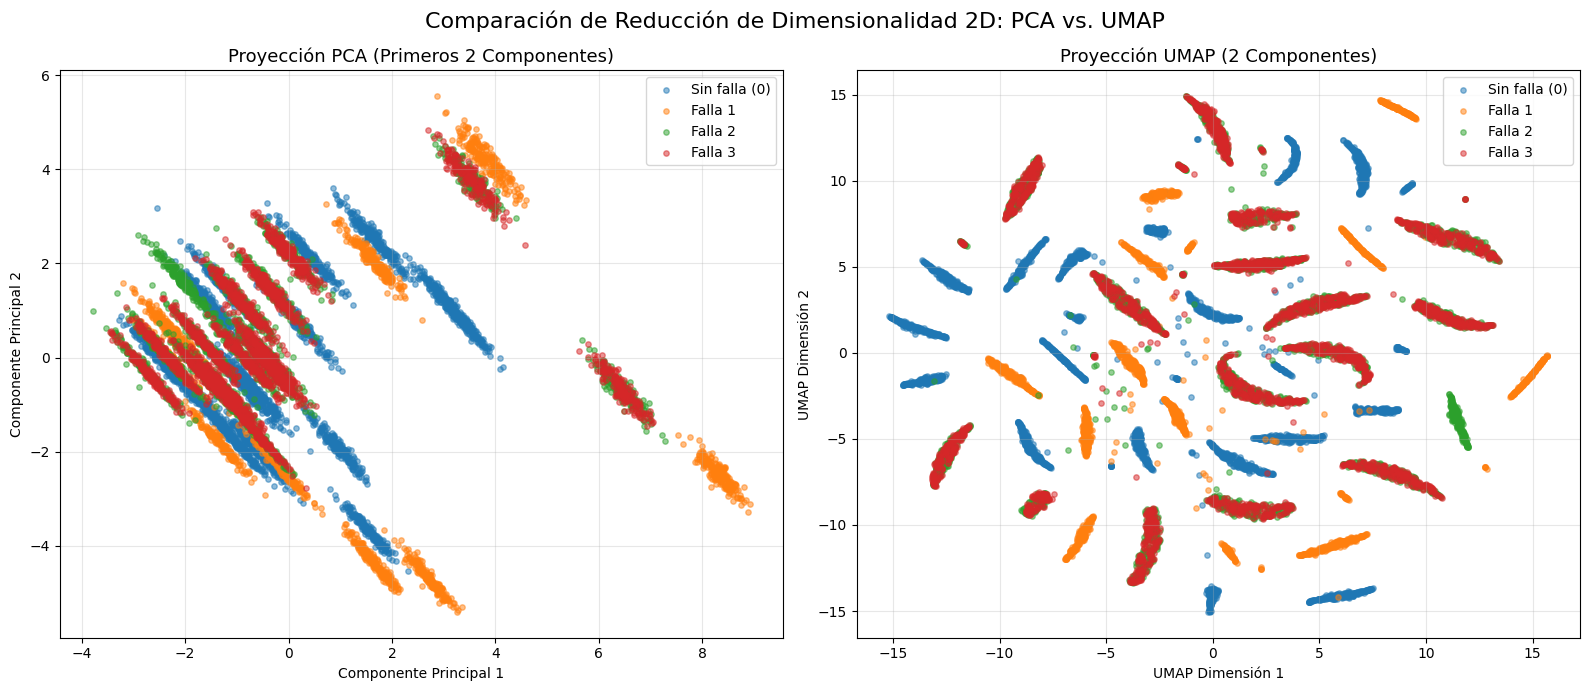

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Clases y colores para consistencia visual
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
target_names = ["Sin falla (0)", "Falla 1", "Falla 2", "Falla 3"]

# 1. Gráfico de PCA (Primeros 2 componentes)
for target, color, name in zip(range(4), colors, target_names):
    indices = (y_test == target)
    axes[0].scatter(X_test_pca[indices, 0], X_test_pca[indices, 1],
                    color=color, label=name, alpha=0.5, s=15)
axes[0].set_title("Proyección PCA (Primeros 2 Componentes)", fontsize=13)
axes[0].set_xlabel("Componente Principal 1")
axes[0].set_ylabel("Componente Principal 2")
axes[0].grid(alpha=0.3)
axes[0].legend(loc='best')

# 2. Gráfico de UMAP (2 componentes)
for target, color, name in zip(range(4), colors, target_names):
    indices = (y_test == target)
    axes[1].scatter(X_test_umap[indices, 0], X_test_umap[indices, 1],
                    color=color, label=name, alpha=0.5, s=15)
axes[1].set_title("Proyección UMAP (2 Componentes)", fontsize=13)
axes[1].set_xlabel("UMAP Dimensión 1")
axes[1].set_ylabel("UMAP Dimensión 2")
axes[1].grid(alpha=0.3)
axes[1].legend(loc='best')

plt.suptitle("Comparación de Reducción de Dimensionalidad 2D: PCA vs. UMAP", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

### Interpretación de los Resultados del Random Forest

A partir de los resultados obtenidos en el entrenamiento, validación cruzada y evaluación en el conjunto de prueba (test), podemos extraer las siguientes conclusiones clave:

#### 1. Rendimiento General y Consistencia (Train vs. Validación vs. Test)
* **Sin Overfitting Severo:** La métrica de F1-macro en el conjunto de **Entrenamiento** ($0.7587$) es muy similar a la de **Validación** ($0.7495$) y a la del conjunto de **Test** ($0.7516$). Esto indica que el modelo generaliza excelente y no está memorizando los datos de entrenamiento.
* **Capacidad predictiva:** El *accuracy* (exactitud) global en test es del **74.41%**.

#### 2. Análisis por Clase (La clave del problema)
Al observar el reporte de clasificación y la matriz de confusión, se hace evidente que el comportamiento del modelo es drásticamente diferente según el tipo de estado/falla:

* **Clase 0 (Sin falla) y Clase 1 (Falla 1): Desempeño Perfecto o Casi Perfecto**
  * **Clase 0:** Tiene una precisión, recall y F1-score de **1.0000** (100% de aciertos). El modelo distingue perfectamente cuándo el motor no tiene fallas.
  * **Clase 1:** Obtiene un F1-score de **0.9993**. Prácticamente no hay errores al identificar esta falla específica.
  
* **Clases 2 y 3: Alta Confusión Mutua**
  * **Clase 2 (Falla 2):** F1-score de **0.5383** (Sensibilidad del 55.67% y Precisión del 52.11%).
  * **Clase 3 (Falla 3):** F1-score de **0.4688** (Sensibilidad del 45.14% y Precisión del 48.77%).
  * **Diagnóstico:** Si observas la matriz de confusión, el modelo rara vez confunde la Clase 2 o 3 con la Clase 0 o 1. Sin embargo, **se confunden masivamente entre sí** (la Falla 2 se clasifica erróneamente como Falla 3, y viceversa). Físicamente o en los datos, estas dos fallas deben compartir patrones muy similares que las variables actuales no logran separar fácilmente.

#### 3. Importancia de las Variables (Feature Importance)
El gráfico de barras de la derecha nos revela qué variables guían las decisiones del bosque:
* Identifica cuáles son las 2 o 3 variables ubicadas en la parte superior (con mayor barra azul). Estas son los sensores o características críticas que permiten separar (al menos) las situaciones sin falla y la Falla 1.
* Las variables situadas en la parte inferior aportan muy poca información al modelo bajo su configuración actual.

#### 4. Sensibilidad a los Hiperparámetros
En los gráficos de evolución de hiperparámetros se observa:
* **Profundidad máxima (`max_depth`):** Limitar la profundidad a 10 ayudó a mantener el modelo robusto y evitar el sobreajuste que suele ocurrir con árboles infinitos (`None`), manteniendo un rendimiento óptimo de manera más eficiente.